# What a DNA language model knows about real eDNA reads — the story, step by step

This notebook tells the results of this repository in order, from the question to the last control.
Every figure and every number is **recomputed here** from the small tables in `data/` (2.7 MB in total),
so `Run All` reproduces the whole page in a few seconds with only `numpy`, `pandas` and `matplotlib`.

**What is computed here and what is not.** Scoring 537,793 sequences with Evo 2 needs a large GPU, and its
raw outputs (per-base probabilities, embeddings) weigh several GB. Those heavy steps were run with the scripts
in `scripts/`; `scripts/00_export_notebook_tables.py` then reduced their outputs to the tables in `data/`.
Each section below names the script that produced its table. The tables contain no read sequences and no
read identifiers.

**The question.** A metabarcoding pipeline decides, read by read: *is this really COI? is it known or new?
is it a chimera, and where is the junction?* Traditional tools answer each of these (length and stop-codon
filters, a COI profile model, alignment to the MIDORI database, uchime). The aim here is not to beat them —
when the answer is in the database, alignment wins — but to test whether a genomic foundation model,
**Evo 2 (7B)**, stores the information needed to answer the same questions **from the read alone**.

## 0 · Definitions used throughout

- **Negative log-likelihood (NLL) of a base.** Evo 2 reads a sequence left to right and, at each position,
  gives a probability to each of A, C, G and T. The NLL at a position is −log p(observed base): 0 when the
  model was certain of the base it saw, large when it was surprised.
- **Per-base perplexity** = exp(NLL) at one position. It reads as "how many bases the model was hesitating
  between": 1 = certain, 4 = no idea. Averaging NLL over a group of reads and then taking exp gives the
  group's per-base perplexity (a geometric mean), which is what the profile figures plot.
- **Perplexity of a read** = exp(mean NLL over its positions): one number per read.
- **Embedding.** Inside the model, every position is represented by 4,096 numbers. Averaging them over the
  read gives one 4,096-number vector per read. It is reduced to 128 principal components, and each component
  is centred and divided by its spread, so that no single direction dominates.
- **AUROC.** The probability that a randomly chosen read of one group gets a higher score than a randomly
  chosen read of the other group. 0.5 = the score cannot tell them apart; 1.0 = perfect separation.
- **Null.** The AUROC obtained when there is nothing to find (a group split against itself, or shuffled
  labels). A result only counts if its 95 % bootstrap interval sits above the null.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.patches import Rectangle
from matplotlib.ticker import PercentFormatter
DATA = Path("data")
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110})
INK, SUB, MUTED, GRID = "#1f2328", "#5b616b", "#8a8a85", "#e7e7e3"

def auroc(pos, neg):
    # Mann-Whitney form of the AUROC, ties counted as half
    pos, neg = np.asarray(pos, float), np.asarray(neg, float)
    r = pd.Series(np.concatenate([pos, neg])).rank().values
    return (r[:pos.size].sum() - pos.size * (pos.size + 1) / 2) / (pos.size * neg.size)

def boot_auc(pos, neg, B=500, seed=0):
    rng = np.random.default_rng(seed); pos, neg = np.asarray(pos), np.asarray(neg)
    v = [auroc(pos[rng.integers(0, len(pos), len(pos))], neg[rng.integers(0, len(neg), len(neg))]) for _ in range(B)]
    return np.percentile(v, [2.5, 97.5])

def boot_med(x, B=1000, seed=0):
    rng = np.random.default_rng(seed); x = np.asarray(x)
    return np.percentile([np.median(x[rng.integers(0, len(x), len(x))]) for _ in range(B)], [2.5, 97.5])

W = 9   # rolling-mean window for per-base profiles (bp)
def roll(v): return np.convolve(np.pad(v, (W // 2, W // 2), mode="edge"), np.ones(W) / W, mode="valid")[:v.size]
print("ready")

ready


## 1 · Simulated contamination: where along the read does each kind change Evo 2's surprise?

**Why start with simulated reads.** On real reads we never know the truth for certain. Simulated reads
are built from real reference barcodes with one known kind of damage each, so we know exactly what changed
and where. The cohorts are: clean references (C0), sequencing error (C1), ancient-DNA damage at two levels
(C4), chimeras whose two parents are close (C2-T2) or distant (C2-T6), and a foreign 16S fragment inserted
into the read (C3).

**What is computed.** For each cohort, the mean NLL at each of the 312 positions over all its reads, turned
into per-base perplexity and smoothed over 9 bp. The first 50 positions are left out of every mean, because
the model has seen too little of the read there and is uncertain for every cohort.

*Table from `scripts/01_simulated_contamination_profile/agg_perbase_phase1.py` (Evo 2 run on an H100).*

,cohort,reads,mean_per_base_perplexity_51_311
0,Reference (C0),1550,1.65
1,C1 · sequencing error,2512,1.67
2,"C4 · aDNA damage, low",2466,1.72
3,"C4 · aDNA damage, high",2533,1.75
4,"C2 · chimera, close parents (T2)",2537,1.46
5,"C2 · chimera, distant parents (T6)",2478,1.72
6,C3 · 16S insert,2557,2.33


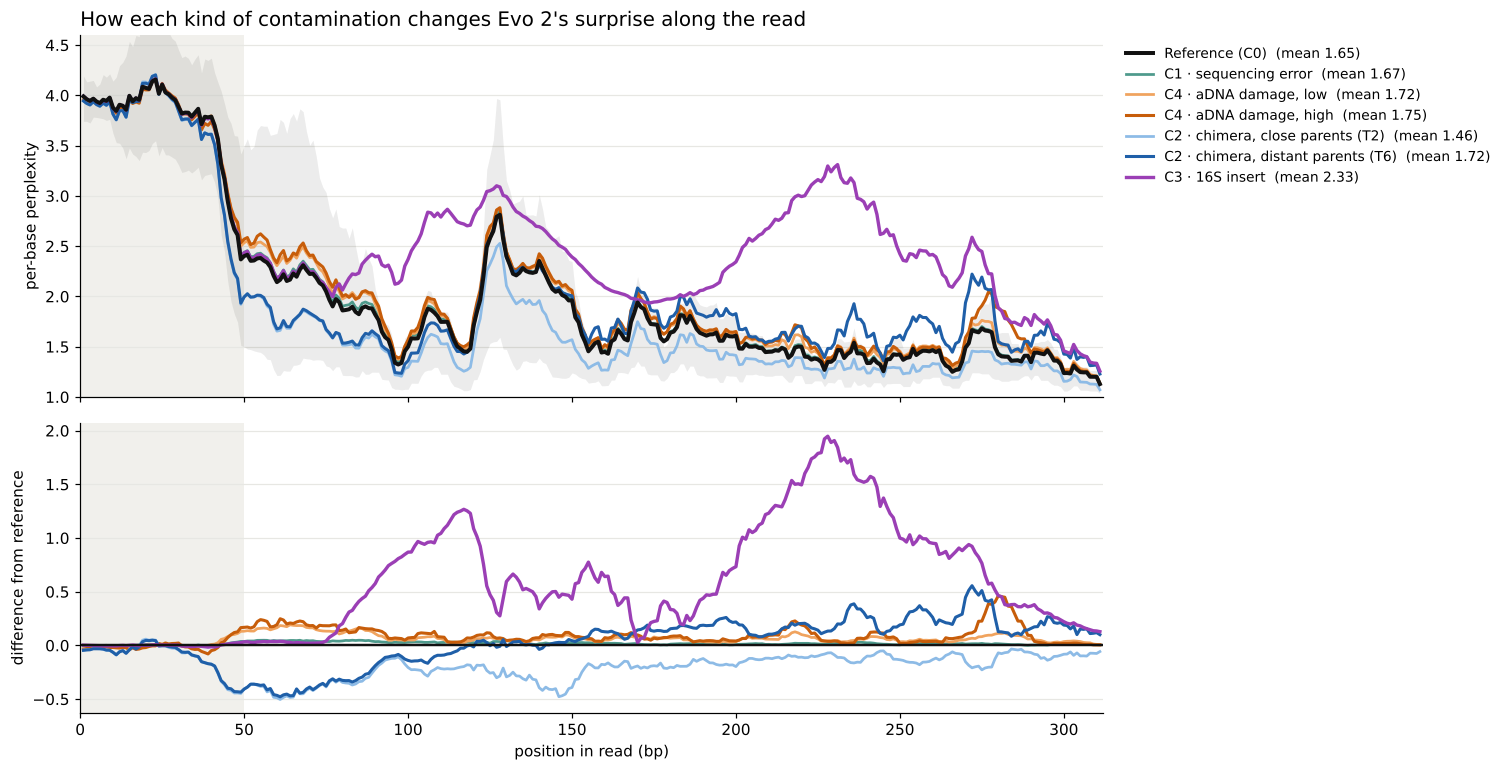

In [2]:
Z = np.load(DATA / "01_simulated_profiles.npz")
COH = [("C0_REF", "Reference (C0)", "#111111", 2.6), ("C1_illumina", "C1 · sequencing error", "#4e9a8c", 1.8),
       ("C4_briggs_low", "C4 · aDNA damage, low", "#f0a35e", 1.8), ("C4_briggs_high", "C4 · aDNA damage, high", "#c75d0a", 2.0),
       ("C2_chimera_T2", "C2 · chimera, close parents (T2)", "#8dbbe6", 1.8),
       ("C2_chimera_T6", "C2 · chimera, distant parents (T6)", "#1f5fa8", 2.0), ("C3_insert", "C3 · 16S insert", "#9b3fb5", 2.2)]
x = np.arange(1, 312)
prof = {k: np.exp(roll(Z[f"{k}__mean"])) for k, *_ in COH}
summary = pd.DataFrame([dict(cohort=lab, reads=int(Z[f"{k}__n"][0]),
                             mean_per_base_perplexity_51_311=round(float(np.exp(Z[f"{k}__mean"][50:].mean())), 2))
                        for k, lab, *_ in COH])
display(summary)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={"height_ratios": [1.25, 1], "hspace": .08})
for ax in (a1, a2):
    ax.axvspan(0, 50, color="#f1f0ec", lw=0, zorder=0); ax.grid(axis="y", color=GRID); ax.set_axisbelow(True); ax.set_xlim(0, 312)
a1.fill_between(x, np.exp(roll(Z["C0_REF__q25"])), np.exp(roll(Z["C0_REF__q75"])), color="#111111", alpha=.08, lw=0)
for (k, lab, col, lw), m in zip(COH, summary.mean_per_base_perplexity_51_311):
    a1.plot(x, prof[k], color=col, lw=lw, zorder=4 if k == "C0_REF" else 3, label=f"{lab}  (mean {m:.2f})")
    if k != "C0_REF": a2.plot(x, prof[k] - prof["C0_REF"], color=col, lw=lw)
a2.axhline(0, color="#111111", lw=1.6)
a1.set_ylim(1, 4.6); a1.set_ylabel("per-base perplexity"); a2.set_ylabel("difference from reference")
a2.set_xlabel("position in read (bp)"); a1.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=9)
a1.set_title("How each kind of contamination changes Evo 2's surprise along the read", loc="left", fontsize=13)
plt.show()

**What it shows.** Each kind of damage has its own footprint. The 16S insert raises surprise exactly where
the foreign fragment sits. Ancient-DNA damage gives a small rise along the whole read. Sequencing error is
almost invisible. Chimeras between close parents are *less* surprising than clean reads, so a single number
per read cannot flag them. Position matters, which is why the per-base view is kept for the rest of the story.

## 2 · Real reads: does one number per read (mean perplexity) see anything?

**The real reads.** Two COI metabarcoding libraries — Brazilian soil (9 samples) and abyssal marine sediment
(ENA PRJEB123800) — cut to the same 312-bp window, scored together with MIDORI database barcodes as known COI.
The off-target classes are abyssal amplicons of the wrong length (368, 401 and 404 bp; scored on a 312-bp
window).

**What is computed.** The distribution of read perplexity in every class, and two AUROCs: off-target vs COI,
and environmental COI vs database COI.

*Table from the H200 scoring run, reduced by `scripts/00_export_notebook_tables.py` to class + perplexity.*

sequences: 200,898
off-target vs COI                 AUROC = 0.860
environmental COI vs database COI AUROC = 0.527


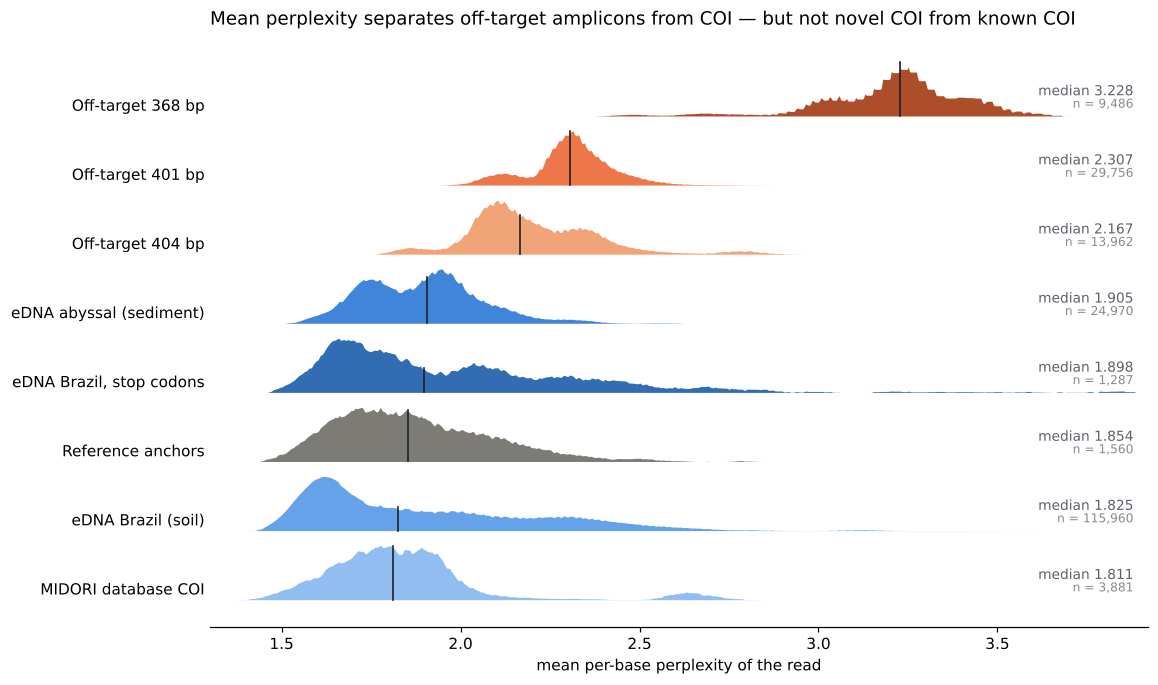

In [3]:
d = pd.read_csv(DATA / "02_real_perplexity.csv.gz")
COI = ["ref_anchor", "midori", "edna_brazil", "edna_abyssal"]
print(f"sequences: {len(d):,}")
print(f"off-target vs COI                 AUROC = {auroc(d[d.cls.str.startswith('abyssal_off')].perplexity, d[d.cls.isin(COI)].perplexity):.3f}")
print(f"environmental COI vs database COI AUROC = {auroc(d[d.cls.isin(['edna_brazil','edna_abyssal'])].perplexity, d[d.cls.isin(['ref_anchor','midori'])].perplexity):.3f}")

real = {c: g.perplexity.to_numpy() for c, g in d.groupby("cls") if len(g) >= 100}
LABEL = {"ref_anchor": "Reference anchors", "midori": "MIDORI database COI", "edna_brazil": "eDNA Brazil (soil)",
         "edna_abyssal": "eDNA abyssal (sediment)", "brazil_stop": "eDNA Brazil, stop codons",
         "abyssal_off404": "Off-target 404 bp", "abyssal_off401": "Off-target 401 bp", "abyssal_off368": "Off-target 368 bp"}
COLOR = {"ref_anchor": "#6f6d67", "midori": "#86b6ef", "edna_brazil": "#5598e7", "edna_abyssal": "#2a78d6",
         "brazil_stop": "#1c5cab", "abyssal_off404": "#f19a6b", "abyssal_off401": "#eb6834", "abyssal_off368": "#a33b12"}
def dens(v, lo=1.3, hi=3.9, nb=420, sm=17):
    e = np.linspace(lo, hi, nb + 1); h, _ = np.histogram(v, bins=e, density=True)
    h = np.convolve(np.pad(h, (sm // 2, sm // 2), mode="edge"), np.ones(sm) / sm, mode="valid")[:nb]
    return (e[:-1] + e[1:]) / 2, h
order = sorted(real, key=lambda c: np.median(real[c]))
fig, ax = plt.subplots(figsize=(11, 7))
for i, c in enumerate(order):
    xs, h = dens(real[c]); h = h / h.max() * .8; med = np.median(real[c])
    ax.fill_between(xs, i, i + h, color=COLOR[c], alpha=.9, lw=0, zorder=3 + 2 * i)
    ax.plot(xs, i + h, color="white", lw=2, zorder=3 + 2 * i)
    ax.plot([med, med], [i, i + np.interp(med, xs, h)], color=INK, lw=1.1, zorder=4 + 2 * i)
    ax.text(3.88, i + .3, f"median {med:.3f}", ha="right", fontsize=9, color=SUB)
    ax.text(3.88, i + .12, f"n = {real[c].size:,}", ha="right", fontsize=8, color=MUTED)
ax.set_yticks([i + .16 for i in range(len(order))]); ax.set_yticklabels([LABEL[c] for c in order])
ax.tick_params(axis="y", length=0); ax.spines["left"].set_visible(False); ax.set_xlim(1.3, 3.92)
ax.set_xlabel("mean per-base perplexity of the read")
ax.set_title("Mean perplexity separates off-target amplicons from COI — but not novel COI from known COI", loc="left", fontsize=12)
plt.show()

**What it shows.** Off-target amplicons sit to the right (AUROC 0.86), but environmental COI sits right on top
of database COI (0.53): one number per read cannot see novelty. And the off-targets it does see are exactly
the ones a length filter already removes. Two questions follow: is the information about novelty somewhere
else in the model (section 4), and what about off-targets that pass the length filter (section 5)?

## 3 · The embedding: a picture of the shared space

**Why a shared space is legitimate.** The real reads were scored on an H200 GPU and the simulated reads on an
H100. The same 1,560 reference sequences were scored in both runs and gave **bit-identical** results, so real
and simulated reads can be placed in one space.

**What is drawn.** Each read's embedding projected onto two axes, by PCA (a linear projection) and by UMAP
(a non-linear one that keeps neighbours together). Three groups are coloured; everything else is grey.

*Coordinates from `scripts/03_embedding_map/map1_build.py` and `w7_figures.py`.*

points drawn: 101,897


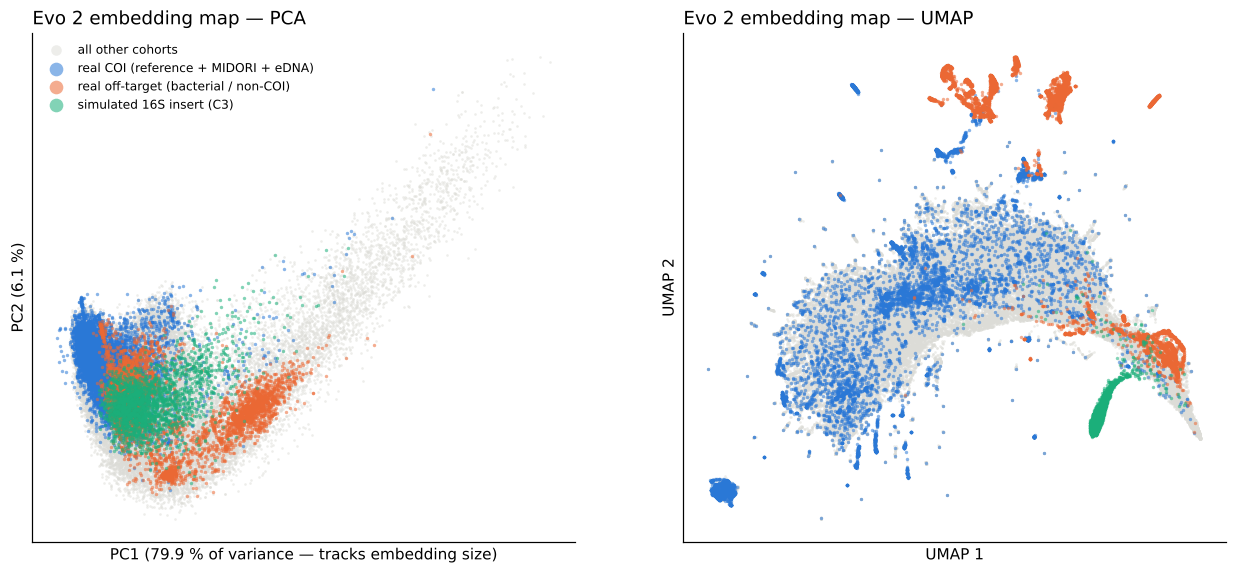

In [4]:
e = pd.read_csv(DATA / "03_embedding_map.csv.gz")
GROUPS = [("real COI (reference + MIDORI + eDNA)", ["REAL:ref_anchor", "REAL:midori", "REAL:edna_brazil", "REAL:edna_abyssal"], "#2a78d6"),
          ("real off-target (bacterial / non-COI)", ["REAL:abyssal_off401", "REAL:abyssal_off404", "REAL:abyssal_off368"], "#eb6834"),
          ("simulated 16S insert (C3)", ["SIM:C3_insert"], "#1baf7a")]
print(f"points drawn: {len(e):,}")
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
for ax, (cx, cy, tag) in zip(axs, [("pc1", "pc2", "PCA"), ("umap1", "umap2", "UMAP")]):
    other = ~e.group.isin(sum([g[1] for g in GROUPS], []))
    ax.scatter(e.loc[other, cx], e.loc[other, cy], s=3, c="#dcdcd7", lw=0, alpha=.5, label="all other cohorts")
    for name, keys, col in GROUPS:
        m = e.group.isin(keys); ax.scatter(e.loc[m, cx], e.loc[m, cy], s=5, c=col, lw=0, alpha=.55, label=name)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"Evo 2 embedding map — {tag}", loc="left")
axs[0].set_xlabel("PC1 (79.9 % of variance — tracks embedding size)"); axs[0].set_ylabel("PC2 (6.1 %)")
axs[1].set_xlabel("UMAP 1"); axs[1].set_ylabel("UMAP 2")
axs[0].legend(loc="upper left", markerscale=4, fontsize=8, frameon=False)
plt.show()

**What it shows, and what it does not.** Real COI, real off-targets and the simulated insert occupy different
regions. But a 2-D picture is not a test: points can look separated by the projection or overlap because of it.
The next two sections measure the separations directly.

## 4 · Novelty: does the embedding know which reads are far from anything in the database?

**The design, and why each choice.**
- *Distance to the database* is measured as the identity of each read to its nearest MIDORI record (vsearch).
- *Known reads* = reads ≥99 % identical to a MIDORI record. *Novel* reads are binned by identity: 98–99 %,
  97–98 %, … down to 70–80 %. Each band is compared with the same known reads, as its own test.
- *One library and one phylum* (Brazilian soil, Ascomycota) for every band, so that a difference cannot come
  from comparing different libraries or different phyla.
- *The score*: a classifier on the embedding, trained on half of the reads and tested on the other half
  (15 random splits). The AUROC is the median over splits, the interval is a bootstrap over reads, and the
  null is the known reads split against themselves.

*Table from `scripts/04_novelty_ladder/w9_dims_and_ci.py`.*

null: 0.497  (95 % band 0.477-0.526)


,identity band (%),n_novel,auroc,ci_lo,ci_hi
1,98-99,2000,0.723,0.696,0.734
2,97-98,2000,0.734,0.720,0.747
3,95-97,2000,0.822,0.809,0.832
4,92-95,2000,0.914,0.906,0.921
5,88-92,2000,0.961,0.954,0.967
6,84-88,2000,0.973,0.969,0.977
7,80-84,282,0.989,0.980,0.993
8,70-80,177,1.000,1.000,1.000


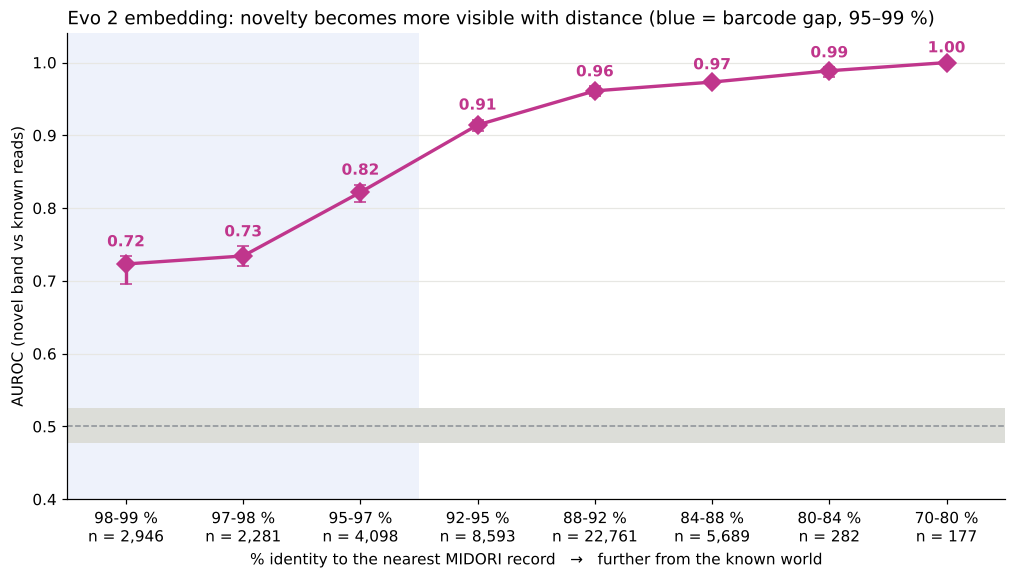

In [5]:
w = pd.read_csv(DATA / "04_novelty_ladder.csv")
lad = w[w.fig == "fig1"].copy(); null = lad[lad.comparison.str.startswith("null")].iloc[0]; lad = lad[~lad.comparison.str.startswith("null")]
lad["n_novel"] = lad.n_a.astype(int)
print(f"null: {null.auroc:.3f}  (95 % band {null.null_lo:.3f}-{null.null_hi:.3f})")
display(lad[["comparison", "n_novel", "auroc", "ci_lo", "ci_hi"]].round(3).rename(columns={"comparison": "identity band (%)"}))

BANDS = ["98-99", "97-98", "95-97", "92-95", "88-92", "84-88", "80-84", "70-80"]
NS = [2946, 2281, 4098, 8593, 22761, 5689, 282, 177]          # reads in each band before subsampling to 2,000
s = lad.set_index("comparison").loc[BANDS]; xx = np.arange(8)
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.axvspan(-.5, 2.5, color="#eef2fb", lw=0, zorder=0); ax.axhspan(null.null_lo, null.null_hi, color="#dcddd8", lw=0, zorder=1)
ax.axhline(.5, color="#8a8f96", ls="--", lw=1); ax.grid(axis="y", color=GRID); ax.set_axisbelow(True)
ax.errorbar(xx, s.auroc, yerr=[s.auroc - s.ci_lo, s.ci_hi - s.auroc], color="#c0368c", lw=2.2, marker="D", ms=8, capsize=4, zorder=4)
for xi, (a, hi) in enumerate(zip(s.auroc, s.ci_hi)): ax.text(xi, hi + .014, f"{a:.2f}", ha="center", fontsize=10, fontweight="bold", color="#c0368c")
ax.set_xticks(xx, [f"{b} %\nn = {n:,}" for b, n in zip(BANDS, NS)]); ax.set_xlim(-.5, 7.5); ax.set_ylim(.4, 1.04)
ax.set_ylabel("AUROC (novel band vs known reads)"); ax.set_xlabel("% identity to the nearest MIDORI record   →   further from the known world")
ax.set_title("Evo 2 embedding: novelty becomes more visible with distance (blue = barcode gap, 95–99 %)", loc="left", fontsize=12)
plt.show()

**Is it just genera?** Different identity bands could hold different genera, and the embedding is known to
separate taxa. So the same test is repeated *inside* single genera, where that explanation is impossible.
A comparison counts only if its whole interval sits above its own null.

In [6]:
g = w[w.fig == "fig2"].copy()
g[["genus", "band"]] = g.comparison.str.split("|", expand=True)
g["clears_null"] = g.ci_lo > g.null_hi
display(g[["genus", "band", "n_a", "n_b", "auroc", "ci_lo", "ci_hi", "null_hi", "clears_null"]].round(3)
        .rename(columns={"n_a": "n novel", "n_b": "n known"}))
print(f"{g.clears_null.sum()} of {len(g)} genus x band comparisons clear their null")

,genus,band,n novel,n known,auroc,ci_lo,ci_hi,null_hi,clears_null
9,Fusarium,98-99,267.0,600.0,0.874,0.802,0.912,0.548,True
10,Purpureocillium,98-99,588.0,211.0,0.824,0.775,0.850,0.519,True
11,Trichoderma,98-99,600.0,600.0,0.633,0.583,0.666,0.553,True
12,Fusarium,97-98,267.0,600.0,0.935,0.912,0.947,0.548,True
13,Purpureocillium,97-98,588.0,115.0,0.834,0.706,0.857,0.519,True
14,Trichoderma,97-98,600.0,532.0,0.728,0.696,0.750,0.553,True
15,Fusarium,95-97,267.0,600.0,0.882,0.844,0.899,0.548,True
16,Purpureocillium,95-97,588.0,178.0,0.827,0.711,0.860,0.519,True
17,Trichoderma,95-97,600.0,600.0,0.776,0.746,0.795,0.553,True


9 of 9 genus x band comparisons clear their null


**What it shows.** In the barcode gap (95–99 %), where a new species is expected, the embedding reaches
0.72–0.82 while mean perplexity was at chance (section 2); further out it climbs to 1.00. Inside single genera
all nine comparisons clear their null, so the signal is not just "a different genus". One caution: *known*
means known to MIDORI, not necessarily seen by Evo 2 during its training.

## 5 · Off-targets that slip through every COI check

**Labels that never look at Evo 2.** Each real read was aligned against eukaryotic COI (MIDORI) and against
bacterial COI-family genes, and assigned to the side its closest relatives are on, with an undecided grey
zone of ±5 bits. Two groups matter here:

- **HIDDEN bacterial-like** — passed *every* COI check in the pipeline (length, stop codons, COI profile),
  yet their closest relatives are bacterial.
- **Stop-codon reads (Brazilian soil)** — right length, no ambiguous bases, good quality, but an in-frame
  stop codon (TAA/TAG) in both possible 312-bp cuts of the window: the stop codon was the only check they
  failed. This is the signature of a nuclear pseudogene copy (NUMT) or of an insertion/deletion error.

**First, where along the read do they differ?** Same per-base view as section 1, now on real reads, each
library against its own eukaryotic COI.

*Profiles from `scripts/05_offtargets/e1_build_table.py` and `e3_features.py`.*

,lib,group,n,mean_ppl_51_311
0,brazil,EUK,110388,1.66
311,brazil,HID_prok,680,1.79
622,brazil,HID_grey,4825,2.13
933,brazil,HID_notCOI,67,3.32
1244,brazil,STOP,1287,1.78
1555,abyssal,EUK,16288,1.66
1866,abyssal,HID_prok,7893,1.69
2177,abyssal,HID_grey,766,1.80
2488,abyssal,HID_notCOI,24,2.62


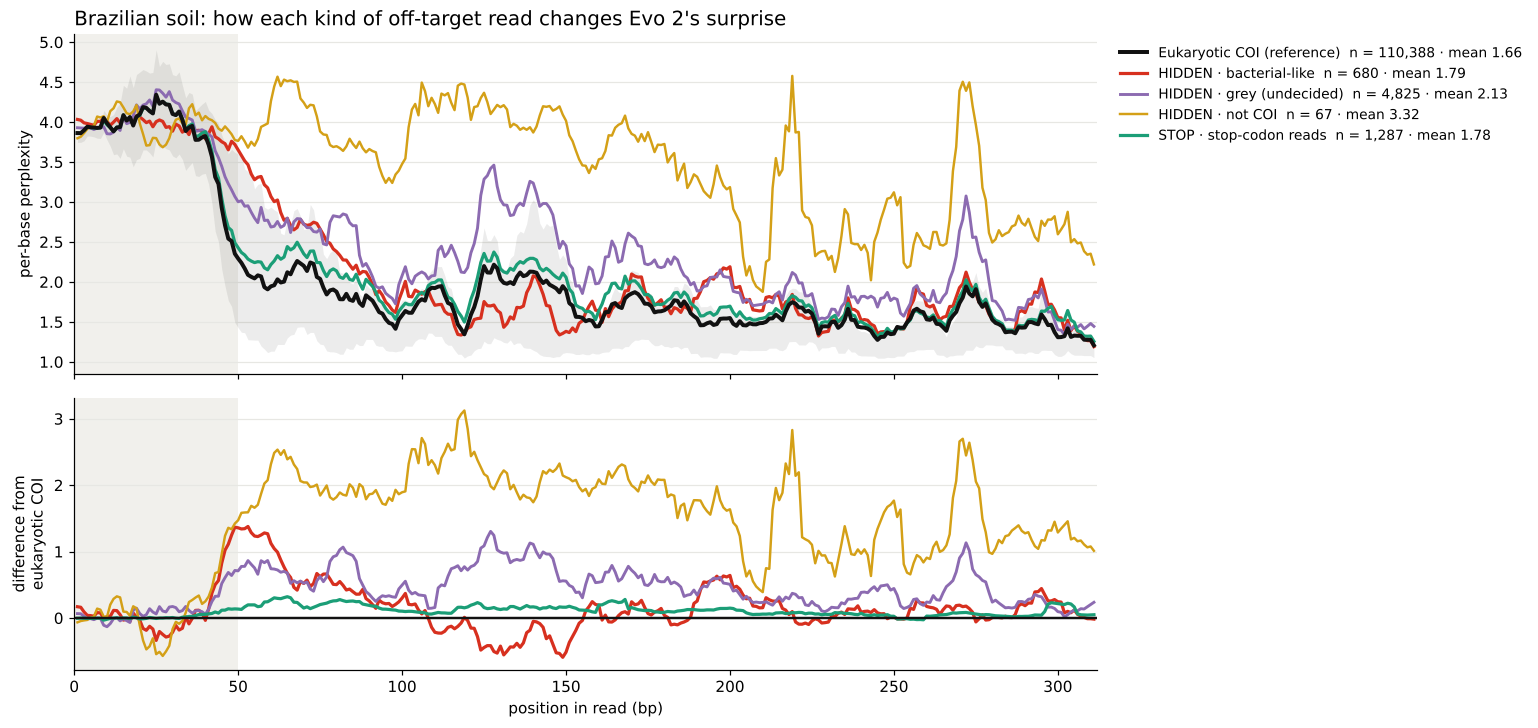

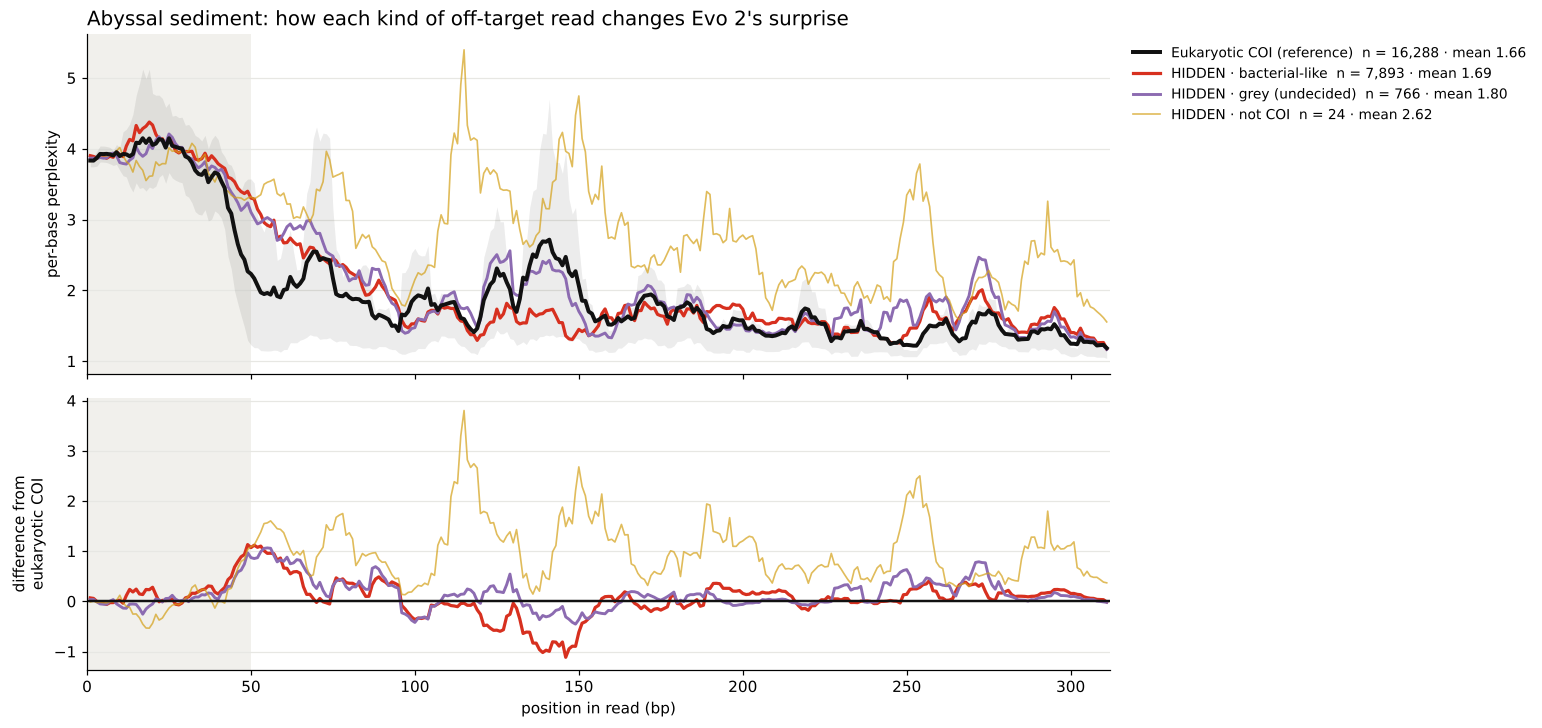

In [7]:
P = pd.read_csv(DATA / "05_offtarget_profiles.csv.gz")
SPEC = {"EUK": ("Eukaryotic COI (reference)", "#111111", 2.6), "HID_prok": ("HIDDEN · bacterial-like", "#d7301f", 2.1),
        "HID_grey": ("HIDDEN · grey (undecided)", "#8c6bb1", 1.9), "HID_notCOI": ("HIDDEN · not COI", "#d4a017", 1.6),
        "STOP": ("STOP · stop-codon reads", "#1b9e77", 2.1)}
display(P.drop_duplicates(["lib", "group"])[["lib", "group", "n", "mean_ppl_51_311"]].round(2))
for lib, name in [("brazil", "Brazilian soil"), ("abyssal", "Abyssal sediment")]:
    Q = P[P.lib == lib]; ref = np.exp(roll(Q[Q.group == "EUK"].mean_nll.values)); xp = np.arange(1, len(ref) + 1)
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [1.25, 1], "hspace": .08})
    for ax in (a1, a2): ax.axvspan(0, 50, color="#f1f0ec", lw=0, zorder=0); ax.grid(axis="y", color=GRID); ax.set_axisbelow(True); ax.set_xlim(0, len(ref) + 1)
    e0 = Q[Q.group == "EUK"]; a1.fill_between(xp, np.exp(roll(e0.q25_nll.values)), np.exp(roll(e0.q75_nll.values)), color="#111111", alpha=.08, lw=0)
    for grp, G in Q.groupby("group", sort=False):
        lab, col, lw = SPEC[grp]; n = int(G.n.iloc[0]); thin = n < 50; prof_g = np.exp(roll(G.mean_nll.values))
        a1.plot(xp, prof_g, color=col, lw=1.1 if thin else lw, alpha=.7 if thin else 1, zorder=4 if grp == "EUK" else 3,
                label=f"{lab}  n = {n:,} · mean {G.mean_ppl_51_311.iloc[0]:.2f}")
        if grp != "EUK": a2.plot(xp, prof_g - ref, color=col, lw=1.1 if thin else lw, alpha=.7 if thin else 1)
    a2.axhline(0, color="#111111", lw=1.6); a1.set_ylabel("per-base perplexity"); a2.set_ylabel("difference from\neukaryotic COI")
    a2.set_xlabel("position in read (bp)"); a1.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=9)
    a1.set_title(f"{name}: how each kind of off-target read changes Evo 2's surprise", loc="left", fontsize=13)
    plt.show()

In the abyssal library the bacterial-like reads have almost the same *mean* as COI (1.69 vs 1.66), but a
different *shape*: they dip below COI around positions 120–150. A per-read average throws that away.

**Then, the test against traditional scores.** Every score — Evo 2's and the traditional ones — is given to
the same classifier (ridge regression), trained and tested on the same splits. Splits keep reads of the same
97 % cluster together, so near-copies of a training read never appear in the test half. AUROC = median of 5
re-splits; interval = bootstrap; grey band = null from shuffled labels.

*Results from `scripts/05_offtargets/e4_compare.py`, checked by `e4_check.py`.*

test,bacterial-like · brazil,bacterial-like · abyssal,stop-codon · brazil
Evo 2 · perplexity,0.671,0.575,0.591
Evo 2 · per-base perplexity,0.997,0.999,0.855
Evo 2 · per-base A/C/G/T,0.999,1.000,0.870
Evo 2 · embedding,0.988,0.998,0.849
GC content,0.920,0.843,0.515
4-mer counts,0.983,1.000,0.675
MIDORI identity,0.857,0.919,0.514
COI profile score,0.556,0.859,0.514


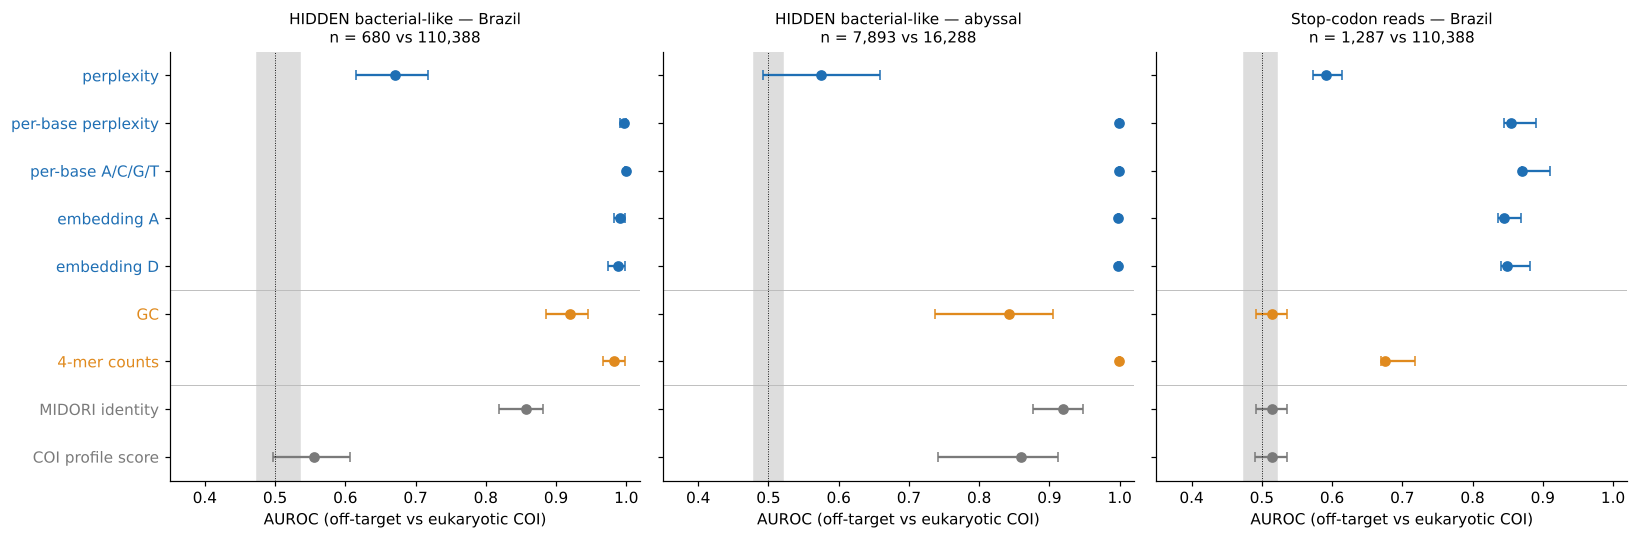

In [8]:
R = pd.read_csv(DATA / "05_offtarget_auroc.csv")
R["test"] = np.where(R.comparison == "STOP_vs_EUK", "stop-codon · " + R.lib, "bacterial-like · " + R.lib)
NAME = {"ppl": "Evo 2 · perplexity", "nll": "Evo 2 · per-base perplexity", "acgt": "Evo 2 · per-base A/C/G/T",
        "embA": "Evo 2 · embedding (centred only)", "embD": "Evo 2 · embedding", "gc": "GC content", "kmer4": "4-mer counts",
        "midori_id": "MIDORI identity", "prof_score0": "COI profile score", "codon3": "codon usage"}
FEATS = ["ppl", "nll", "acgt", "embD", "gc", "kmer4", "midori_id", "prof_score0"]
tab = R[R.feature.isin(FEATS)].pivot(index="feature", columns="test", values="auroc").loc[FEATS]
tab.index = [NAME[f] for f in FEATS]
display(tab[["bacterial-like · brazil", "bacterial-like · abyssal", "stop-codon · brazil"]].round(3))

EVO, SEQ, DB = ["ppl", "nll", "acgt", "embA", "embD"], ["gc", "kmer4"], ["midori_id", "prof_score0"]
COLF = {**{k: "#1f6fb4" for k in EVO}, **{k: "#e08a1e" for k in SEQ}, **{k: "#7a7a7a" for k in DB}}
LABF = {"ppl": "perplexity", "nll": "per-base perplexity", "acgt": "per-base A/C/G/T", "embA": "embedding A", "embD": "embedding D",
        "gc": "GC", "kmer4": "4-mer counts", "midori_id": "MIDORI identity", "prof_score0": "COI profile score"}
F = EVO + SEQ + DB
fig, axs = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, (cmp, lib, title) in zip(axs, [("HID_prok_vs_EUK", "brazil", "HIDDEN bacterial-like — Brazil"),
                                        ("HID_prok_vs_EUK", "abyssal", "HIDDEN bacterial-like — abyssal"),
                                        ("STOP_vs_EUK", "brazil", "Stop-codon reads — Brazil")]):
    G = R[(R.comparison == cmp) & (R.lib == lib)].set_index("feature")
    for i, f in enumerate(F):
        r = G.loc[f]; ax.errorbar(r.auroc, i, xerr=[[max(r.auroc - r.ci_lo, 0)], [max(r.ci_hi - r.auroc, 0)]], fmt="o", color=COLF[f], ms=6, capsize=3)
    ax.axvspan(G.null_lo.min(), G.null_hi.max(), color="#dddddd", zorder=0); ax.axvline(.5, color="k", lw=.6, ls=":")
    ax.set_yticks(range(len(F))); ax.set_yticklabels([LABF[f] for f in F]); ax.set_ylim(len(F) - .5, -.5); ax.set_xlim(.35, 1.02)
    for t, f in zip(ax.get_yticklabels(), F): t.set_color(COLF[f])
    ax.axhline(len(EVO) - .5, color="#bbbbbb", lw=.6); ax.axhline(len(EVO) + len(SEQ) - .5, color="#bbbbbb", lw=.6)
    ax.set_xlabel("AUROC (off-target vs eukaryotic COI)"); ax.set_title(f"{title}\nn = {int(G.n_pos.iloc[0]):,} vs {int(G.n_neg.iloc[0]):,}", fontsize=10)
plt.tight_layout(); plt.show()

**What it shows — two different stories.**

- *Bacterial-like reads are given away by their composition.* Evo 2's per-base and embedding scores separate
  them almost perfectly, but so does counting 4-mers. Here the model confirms information that simpler
  features already carry.
- *Stop-codon reads show something else.* A stop-codon check finds them perfectly, because that is how the
  group was defined, so this is not a better filter. What it shows is that the model — told nothing about
  reading frames or the genetic code — reaches 0.85–0.87 on them, while GC content, MIDORI identity and the
  COI profile score stay at chance on the same reads. The information that something breaks the coding
  structure is stored in the model.

## 6 · Chimeras: can Evo 2 tell where two templates were joined?

**Why simulated chimeras.** In a real read we never know where the junction is. In the simulated C2 cohorts
we do, to the base. T6 = the two parents are distantly related; T2 = closely related.

**Three questions, three computations.**

1. *Detection* — is this read a chimera at all? Evo 2's score is the per-position uncertainty (entropy) of
   its A/C/G/T prediction. The benchmark, uchime_ref, is given the reference database, which contains both
   parents of every chimera at 100 % identity.
2. *Localisation* — where is the junction? At each position, compare the base the model expected most with
   the base it saw: log p(most likely base) − log p(observed base). Past a junction the model is still
   following parent A and keeps expecting parent A's bases, so this score jumps; its crossing point is the
   estimated junction. Chance = the same estimates scored against the true junctions of other reads.
3. *Confidence* — can the model's own detection score tell which localisation calls to trust?

*Tables from `scripts/06_chimeras/run_chain.sh` (j1–j7).*

uchime_ref (given both parents)    AUROC 1.000  [1.000, 1.000]
Evo 2 · entropy (no reference)     AUROC 0.832  [0.807, 0.855]
within 20 bp: 58%   within 4 bp: 29%   median error 13 bp in this seed (chance 51 bp; 14 bp averaged over 5 seeds, see the tier table)
median error by fifth of the detection score (low -> high): ['38 bp', '23 bp', '12 bp', '9 bp', '7 bp']


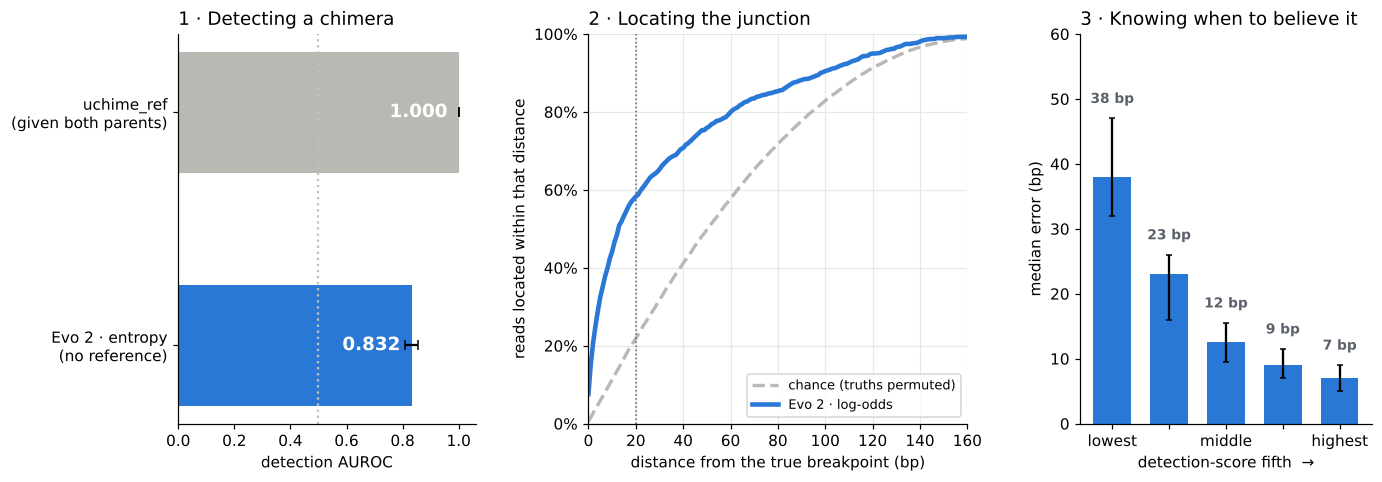

In [9]:
b = pd.read_csv(DATA / "06_chimera_detection.csv"); neg = b[b.is_chimera == 0]; t6 = b[b.cohort == "C2_chimera_T6"]
det = {"uchime_ref (given both parents)": (auroc(t6.uchime_ref, neg.uchime_ref), boot_auc(t6.uchime_ref.values, neg.uchime_ref.values)),
       "Evo 2 · entropy (no reference)": (auroc(t6.evo2_entropy, neg.evo2_entropy), boot_auc(t6.evo2_entropy.values, neg.evo2_entropy.values))}
for k, (v, ci) in det.items(): print(f"{k:34s} AUROC {v:.3f}  [{ci[0]:.3f}, {ci[1]:.3f}]")

L6 = pd.read_csv(DATA / "06_chimera_localisation_T6.csv"); err = L6.err.values
rng = np.random.default_rng(7)
chance = np.concatenate([np.abs(L6.est.values - L6.bp.values[rng.permutation(len(L6))]) for _ in range(20)])
print(f"within 20 bp: {(err <= 20).mean():.0%}   within 4 bp: {(err <= 4).mean():.0%}   median error {np.median(err):.0f} bp in this seed (chance {np.median(chance):.0f} bp; 14 bp averaged over 5 seeds, see the tier table)")

q = pd.read_csv(DATA / "06_chimera_confidence_T6.csv"); q["fifth"] = pd.qcut(q.score, 5, labels=[1, 2, 3, 4, 5])
med = q.groupby("fifth", observed=True).err.median(); cis = [boot_med(h.err.values) for _, h in q.groupby("fifth", observed=True)]
print("median error by fifth of the detection score (low -> high):", [f"{m:.0f} bp" for m in med.values])

fig = plt.figure(figsize=(14, 4.6)); gs = fig.add_gridspec(1, 3, width_ratios=[1.02, 1.3, 1.0], wspace=.35)
aA, aB, aC = [fig.add_subplot(gs[i]) for i in range(3)]
vals = [v for v, _ in det.values()]; ci = [c for _, c in det.values()]
aA.barh([1, 0], vals, height=.52, color=["#b9b8b2", "#2a78d6"], xerr=[[v - c[0] for v, c in zip(vals, ci)], [c[1] - v for v, c in zip(vals, ci)]], capsize=3)
for yy, v in zip([1, 0], vals): aA.text(v - .04, yy, f"{v:.3f}", va="center", ha="right", color="white", fontsize=12, fontweight="bold")
aA.set_yticks([1, 0], ["uchime_ref\n(given both parents)", "Evo 2 · entropy\n(no reference)"]); aA.set_xlim(0, 1.06)
aA.axvline(.5, color="#c3c2b7", ls=":"); aA.set_xlabel("detection AUROC"); aA.set_title("1 · Detecting a chimera", loc="left")
grid = np.arange(161)
aB.plot(grid, [(chance <= t).mean() for t in grid], color="#b9b8b2", lw=2.2, ls="--", label="chance (truths permuted)")
aB.plot(grid, [(err <= t).mean() for t in grid], color="#2a78d6", lw=3, label="Evo 2 · log-odds")
aB.axvline(20, color=SUB, lw=1, ls=":"); aB.set_xlim(0, 160); aB.set_ylim(0, 1); aB.yaxis.set_major_formatter(PercentFormatter(1.0))
aB.set_xlabel("distance from the true breakpoint (bp)"); aB.set_ylabel("reads located within that distance")
aB.legend(loc="lower right", fontsize=8.5); aB.set_title("2 · Locating the junction", loc="left"); aB.grid(color=GRID)
bars = aC.bar(range(5), med.values, width=.66, color="#2a78d6", yerr=[[m - c[0] for m, c in zip(med.values, cis)], [c[1] - m for m, c in zip(med.values, cis)]], capsize=2)
aC.bar_label(bars, fmt="%.0f bp", padding=8, fontsize=9, color=SUB, fontweight="bold")
aC.set_xticks(range(5), ["lowest", "", "middle", "", "highest"]); aC.set_xlabel("detection-score fifth  →")
aC.set_ylabel("median error (bp)"); aC.set_ylim(0, 60); aC.set_title("3 · Knowing when to believe it", loc="left")
plt.show()

**Does this hold for shallower chimeras?** The same localisation score across all five divergence tiers
(mean over 5 seeds of the median error, and its chance level):

In [10]:
t = pd.read_csv(DATA / "06_chimera_localisation_by_tier.csv")
t = t[t.channel == "logodds"].groupby("cohort")[["med_abs_err", "chance_med_abs_err"]].mean().round(1)
t.index = [i.replace("C2_chimera_", "") for i in t.index]
display(t.rename(columns={"med_abs_err": "median error (bp)", "chance_med_abs_err": "chance (bp)"}))

,median error (bp),chance (bp)
T2,63.1,61.4
T3,61.8,62.2
T4,54.1,59.0
T5,34.0,53.3
T6,14.0,51.0


**What it shows.** Alignment wins detection when both parents are in its database (1.000 vs 0.832) — a test it
cannot lose. But uchime reports no junction position at all, while Evo 2, given only the read, places the
junction within 20 bp for 58 % of deep chimeras, and its own detection score says which calls to trust
(38 bp → 7 bp from the lowest to the highest fifth). The limits are clear too: localisation works only for
distant parents (T5–T6); for T2–T4 it is at chance. And the errors are a mixture — a little over half the
reads are placed precisely and the rest are close to chance — so the median should never be quoted alone.

---

## Summary

1. **Off-targets.** Evo 2 recognises reads that are not eukaryotic COI, including reads that passed every
   COI check; for bacterial reads composition alone already does this, while for stop-codon reads the model
   carries coding-structure information that composition and database scores do not.
2. **Novelty.** Mean perplexity cannot see it; the embedding can, and the separation grows with distance from
   the database, also inside single genera.
3. **Chimeras.** Without any reference, Evo 2 locates the junction of deep chimeras and knows when its call is
   reliable; shallow chimeras remain invisible to it.

*Part of an ongoing Licenciatura thesis (UBA / IQUIBICEN). Author: Maia Kaplan.*